# 04 · Limpieza por drift (experimento #2)

**Etapa 4 del plan** (`fichas/etapa_4_limpieza_drift.md`). Mide si sacar o neutralizar las variables con drift **sube la ganancia**, con el mismo protocolo del `02`: pruebas A y B, 10 semillas, meseta suavizada y ganancia solo con `BAJA+2`.

**Variantes acumulativas:** cada una suma un cambio a la anterior.

| Variante | Cambio sobre la anterior |
|---|---|
| **V0** | Línea base del `02`. **No se reentrena:** se leen sus curvas |
| **V1** | − `cprestamos_personales`, `mprestamos_personales` ("variable veneno") |
| **V2** | − `Master_fultimo_cierre`, `Visa_fultimo_cierre` (rotas en `202106`) |
| **V3** | − `Master_Finiciomora`, `Visa_Finiciomora` (PSI de 3–6) |
| **V4** | `ccajas_depositos` → `NA` en `202105` (100 % en cero ese mes) |
| **V5** | **No acumulativa:** V4 con los préstamos de vuelta (solo saca las variables rotas). Se agregó después del submit de V4 (pública 83,63 contra 88,09), para separar los préstamos del resto. Solo con `z470_bajas` |

Las semillas son las mismas en todas las variantes, así que la comparación es **pareada**, semilla por semilla. Las curvas ya calculadas no se recalculan: al agregar V5, solo se entrena V5.

## 1. Parámetros

`MODO_RAPIDO = True` corre 1 semilla para medir el tiempo. Con `False` corre las 10. Igual que el `02`, retoma si se corta.

In [17]:
from itertools import product
from pathlib import Path
import json
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

# --- Parámetros -------------------------------------------------------------
MODO_RAPIDO = False             # True: 1 semilla (medir tiempos) · False: 10 semillas

CONFIGS = ['z470_bajas', 'z601_baja2']   # decisión 1 de la ficha

# Cambios acumulativos: cada variante suma su paso a la anterior
PASOS = [
    ('V1', {'excluir': ['cprestamos_personales', 'mprestamos_personales']}),
    ('V2', {'excluir': ['Master_fultimo_cierre', 'Visa_fultimo_cierre']}),
    ('V3', {'excluir': ['Master_Finiciomora', 'Visa_Finiciomora']}),
    ('V4', {'na_en_mes': {'ccajas_depositos': [202105]}}),
]
V5_CONFIGS = ['z470_bajas']     # V5 (no acumulativa) solo con esta configuración

BASE_PARQUET = Path('../data/competencia_01_base.parquet')
EXP02 = Path('../exp/02_linea_base')
EXP = Path('../exp/04_drift')
CURVAS = EXP / 'curvas'
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

CURVAS.mkdir(parents=True, exist_ok=True)
assert (EXP02 / 'configuraciones.json').exists(), 'Falta la salida del 02'

config02 = json.loads((EXP02 / 'configuraciones.json').read_text())
HIPERPARAMETROS = config02['hiperparametros']
CLASES = config02['clases']
PRUEBAS = config02['pruebas']
CORTES = config02['cortes']
VENTANA_SUAVIZADO = config02['ventana_suavizado']
GANANCIA_ACIERTO, COSTO_ESTIMULO = config02['ganancia_acierto'], config02['costo_estimulo']

SEMILLAS_BACKTEST = json.loads((EXP02 / 'semillas.json').read_text())['semillas'][:10]
SEMILLAS_A_USAR = SEMILLAS_BACKTEST[:1] if MODO_RAPIDO else SEMILLAS_BACKTEST

# Variantes acumuladas: V0 = línea base
VARIANTES = {'V0': {'excluir': [], 'na_en_mes': {}}}
anterior = VARIANTES['V0']
for nombre, paso in PASOS:
    actual = {'excluir': anterior['excluir'] + paso.get('excluir', []),
              'na_en_mes': {**anterior['na_en_mes'], **paso.get('na_en_mes', {})}}
    VARIANTES[nombre] = actual
    anterior = actual

# V5: V4 con los préstamos de vuelta (solo saca las variables rotas)
VARIANTES['V5'] = {'excluir': [c for c in VARIANTES['V4']['excluir'] if c not in dict(PASOS)['V1']['excluir']],
                   'na_en_mes': dict(VARIANTES['V4']['na_en_mes'])}


def corre(config, variante):
    """V5 solo se corre con las configuraciones de V5_CONFIGS."""
    return variante != 'V5' or config in V5_CONFIGS


# El 03 lee este archivo para hacer un submit con una variante
(EXP / 'variantes.json').write_text(json.dumps(VARIANTES, indent=2))
for nombre, v in VARIANTES.items():
    print(nombre, '· excluye:', v['excluir'] or '—', '· NA:', v['na_en_mes'] or '—')

V0 · excluye: — · NA: —
V1 · excluye: ['cprestamos_personales', 'mprestamos_personales'] · NA: —
V2 · excluye: ['cprestamos_personales', 'mprestamos_personales', 'Master_fultimo_cierre', 'Visa_fultimo_cierre'] · NA: —
V3 · excluye: ['cprestamos_personales', 'mprestamos_personales', 'Master_fultimo_cierre', 'Visa_fultimo_cierre', 'Master_Finiciomora', 'Visa_Finiciomora'] · NA: —
V4 · excluye: ['cprestamos_personales', 'mprestamos_personales', 'Master_fultimo_cierre', 'Visa_fultimo_cierre', 'Master_Finiciomora', 'Visa_Finiciomora'] · NA: {'ccajas_depositos': [202105]}
V5 · excluye: ['Master_fultimo_cierre', 'Visa_fultimo_cierre', 'Master_Finiciomora', 'Visa_Finiciomora'] · NA: {'ccajas_depositos': [202105]}


## 2. Datos

Las variables de la línea base son todas menos la clase y `foto_mes`, como en el `02`. Cada variante saca las suyas. La transformación a `NA` se aplica **sobre la copia** de las filas de entrenamiento o de prueba, nunca sobre `df`.

In [18]:
t0 = time.time()
df = duckdb.sql(f"select * from read_parquet('{BASE_PARQUET.as_posix()}')").df()
VARIABLES_BASE = [c for c in df.columns if c not in config02['variables_excluidas']]
print(f'{len(df):,} filas · {len(VARIABLES_BASE)} variables en la línea base · {time.time() - t0:.0f} s')


def variables_de(variante):
    return [c for c in VARIABLES_BASE if c not in VARIANTES[variante]['excluir']]


def matriz(indices, variante):
    """X de la variante para unas filas, con sus transformaciones a NA (sobre una copia)."""
    X = df[variables_de(variante)].iloc[indices].copy()
    meses = df['foto_mes'].iloc[indices].to_numpy()
    for columna, meses_na in VARIANTES[variante]['na_en_mes'].items():
        X.loc[np.isin(meses, meses_na), columna] = np.nan
    return X


def particion(prueba):
    meses = PRUEBAS[prueba]
    es_train = df['foto_mes'].isin(meses['train']) & df['clase_ternaria'].notna()
    es_test = df['foto_mes'] == meses['test']
    return np.flatnonzero(es_train), np.flatnonzero(es_test)


# Controles 2 y 3 de la ficha
cantidades = {v: len(variables_de(v)) for v in VARIANTES}
print('Variables por variante:', cantidades)
assert cantidades == {'V0': 153, 'V1': 151, 'V2': 149, 'V3': 147, 'V4': 147, 'V5': 149}
assert {'cprestamos_personales', 'mprestamos_personales'} <= set(variables_de('V5')), 'V5 tiene que tener los préstamos'
_, i_test_B = particion('B')                       # B predice 202105
X_prueba = matriz(i_test_B, 'V4')
assert X_prueba['ccajas_depositos'].isna().all(), 'V4: ccajas_depositos tiene que ser NA en 202105'
assert df['ccajas_depositos'].notna().all(), 'df no se tiene que modificar'
del X_prueba

983,061 filas · 153 variables en la línea base · 1 s
Variables por variante: {'V0': 153, 'V1': 151, 'V2': 149, 'V3': 147, 'V4': 147, 'V5': 149}


## 3. Ganancia (mismas funciones que el `02`)

In [19]:
def curva_ganancia(prob, es_baja2, largo=LARGO_CURVA):
    orden = np.argsort(-prob, kind='stable')
    ganancia = np.where(es_baja2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
    return np.cumsum(ganancia)[:largo].astype(np.float64)


def suavizar(curva, ventana=VENTANA_SUAVIZADO):
    return pd.Series(curva).rolling(ventana, center=True, min_periods=ventana).mean().to_numpy()


def meseta(curva):
    s = suavizar(curva)
    i = int(np.nanargmax(s))
    return i + 1, float(s[i])

## 4. Backtests de V1 a V4

V0 se lee de `../exp/02_linea_base/curvas/`. El resto se entrena acá, con los hiperparámetros del `02`.

In [20]:
def archivo_curva(config, variante, prueba, semilla):
    if variante == 'V0':
        return EXP02 / 'curvas' / f'{config}_{prueba}_s{semilla}.npz'
    return CURVAS / f'{config}_{variante}_{prueba}_s{semilla}.npz'


def correr_modelo(config, variante, prueba, semilla):
    hiper, clase = config.split('_', 1)
    i_train, i_test = particion(prueba)
    y_train = df['clase_ternaria'].iloc[i_train].isin(CLASES[clase]).astype(int).to_numpy()
    params = dict(HIPERPARAMETROS[hiper])
    rondas = params.pop('num_iterations')
    params['seed'] = semilla
    modelo = lgb.train(params, lgb.Dataset(matriz(i_train, variante), label=y_train), num_boost_round=rondas)
    prob = modelo.predict(matriz(i_test, variante))
    es_baja2 = (df['clase_ternaria'].iloc[i_test] == 'BAJA+2').to_numpy()
    np.savez(archivo_curva(config, variante, prueba, semilla),
             curva=curva_ganancia(prob, es_baja2), auc=roc_auc_score(es_baja2, prob))


faltan_v0 = [c for c in product(CONFIGS, ['V0'], PRUEBAS, SEMILLAS_A_USAR) if not archivo_curva(*c).exists()]
assert not faltan_v0, f'Faltan curvas del 02 (correrlo completo): {faltan_v0[:3]}'

corridas = [c for c in product(CONFIGS, [v for v in VARIANTES if v != 'V0'], PRUEBAS, SEMILLAS_A_USAR) if corre(*c[:2])]
pendientes = [c for c in corridas if not archivo_curva(*c).exists()]
print(f'{len(corridas)} modelos · {len(pendientes)} pendientes')

t_total = time.time()
for k, (config, variante, prueba, semilla) in enumerate(pendientes, 1):
    t0 = time.time()
    correr_modelo(config, variante, prueba, semilla)
    print(f'[{k}/{len(pendientes)}] {config} · {variante} · {prueba} · semilla {semilla} · {time.time() - t0:.0f} s')
print(f'Listo en {(time.time() - t_total) / 60:.1f} min')

180 modelos · 20 pendientes
[1/20] z470_bajas · V5 · A · semilla 294103 · 8 s
[2/20] z470_bajas · V5 · A · semilla 342929 · 13 s
[3/20] z470_bajas · V5 · A · semilla 161093 · 12 s
[4/20] z470_bajas · V5 · A · semilla 677561 · 12 s
[5/20] z470_bajas · V5 · A · semilla 431077 · 13 s
[6/20] z470_bajas · V5 · A · semilla 330679 · 13 s
[7/20] z470_bajas · V5 · A · semilla 511579 · 12 s
[8/20] z470_bajas · V5 · A · semilla 312773 · 12 s
[9/20] z470_bajas · V5 · A · semilla 118147 · 12 s
[10/20] z470_bajas · V5 · A · semilla 567529 · 12 s
[11/20] z470_bajas · V5 · B · semilla 294103 · 8 s
[12/20] z470_bajas · V5 · B · semilla 342929 · 8 s
[13/20] z470_bajas · V5 · B · semilla 161093 · 8 s
[14/20] z470_bajas · V5 · B · semilla 677561 · 7 s
[15/20] z470_bajas · V5 · B · semilla 431077 · 8 s
[16/20] z470_bajas · V5 · B · semilla 330679 · 9 s
[17/20] z470_bajas · V5 · B · semilla 511579 · 8 s
[18/20] z470_bajas · V5 · B · semilla 312773 · 8 s
[19/20] z470_bajas · V5 · B · semilla 118147 · 9 s
[20

## 5. Resumen por variante

La misma tabla que el `02`, para cada configuración y variante. El control 1 de la ficha: V0 tiene que dar igual que en el `02`.

In [21]:
def cargar(config, variante, prueba, semillas=SEMILLAS_A_USAR):
    datos = [np.load(archivo_curva(config, variante, prueba, s)) for s in semillas]
    return np.vstack([d['curva'] for d in datos]), np.array([float(d['auc']) for d in datos])


filas, promedios, por_semilla = [], {}, {}
for config, variante, prueba in product(CONFIGS, VARIANTES, PRUEBAS):
    if not corre(config, variante):
        continue
    curvas, aucs = cargar(config, variante, prueba)
    promedio = curvas.mean(axis=0)
    promedios[(config, variante, prueba)] = promedio
    por_semilla[(config, variante, prueba)] = np.array([meseta(c)[1] for c in curvas])
    n_mes, g_mes = meseta(promedio)
    fila = {'config': config, 'variante': variante, 'prueba': prueba, 'semillas': len(curvas),
            'N_meseta': n_mes, 'ganancia_meseta': g_mes,
            'ganancia_media': por_semilla[(config, variante, prueba)].mean(),
            'ganancia_desvio': por_semilla[(config, variante, prueba)].std(ddof=1) if len(curvas) > 1 else np.nan,
            'auc_medio': aucs.mean()}
    fila.update({f'g_{n}': promedio[n - 1] for n in CORTES})
    filas.append(fila)

resumen = pd.DataFrame(filas)
resumen.to_csv(EXP / ('resumen_rapido.csv' if MODO_RAPIDO else 'resumen.csv'), index=False)

if not MODO_RAPIDO:   # control 1: V0 igual que en el 02
    r02 = pd.read_csv(EXP02 / 'resumen.csv').set_index(['config', 'prueba'])['ganancia_meseta']
    for config, prueba in product(CONFIGS, PRUEBAS):
        v0 = resumen.query('config == @config and variante == "V0" and prueba == @prueba')['ganancia_meseta'].iloc[0]
        assert abs(v0 - r02[(config, prueba)]) < 1, f'V0 no reproduce el 02 en {config} {prueba}'
    print('Control 1 OK: V0 reproduce el 02')

(resumen.pivot_table(index=['config', 'variante'], columns='prueba', values=['ganancia_meseta', 'ganancia_desvio', 'N_meseta'])
        .style.format('{:,.0f}'))

Control 1 OK: V0 reproduce el 02


## 6. Comparación pareada: ¿cada paso suma?

Para cada configuración y prueba, cada variante se compara contra **la anterior**, semilla por semilla, con la meseta de cada semilla. **V5** se compara contra V0 (¿sacar solo las rotas suma?) y contra V4 (¿devolver los préstamos suma?):
- **`dif_media`:** diferencia promedio, en millones;
- **`mejoran`:** en cuántas de las 10 semillas mejora;
- **`p`:** test de Wilcoxon pareado, solo con 10 semillas.

**Regla de la ficha ("ante la duda, sacar")**, columna `adoptar`: se adopta el paso si mejora en al menos una prueba y en ninguna empeora con p < 0,05.

In [22]:
acumulativas = [v for v in VARIANTES if v != 'V5']
PARES = list(zip(acumulativas[:-1], acumulativas[1:])) + [('V0', 'V5'), ('V4', 'V5')]
filas = []
for config in CONFIGS:
    for ant, var in PARES:
        if not corre(config, var):
            continue
        fila = {'config': config, 'paso': f'{ant} → {var}'}
        empeora_signif, mejora_alguna = False, False
        for prueba in PRUEBAS:
            d = por_semilla[(config, var, prueba)] - por_semilla[(config, ant, prueba)]
            p = wilcoxon(d).pvalue if len(d) >= 6 and np.any(d != 0) else np.nan
            fila[f'{prueba}_dif_media'] = d.mean() / 1e6
            fila[f'{prueba}_mejoran'] = f'{(d > 0).sum()}/{len(d)}'
            fila[f'{prueba}_p'] = p
            mejora_alguna |= d.mean() > 0
            empeora_signif |= (d.mean() < 0) and (p < 0.05)
        fila['adoptar'] = (not empeora_signif) and (mejora_alguna or len(SEMILLAS_A_USAR) > 1)
        filas.append(fila)

comparacion = pd.DataFrame(filas)
comparacion.to_csv(EXP / ('comparacion_rapido.csv' if MODO_RAPIDO else 'comparacion.csv'), index=False)
comparacion.style.format({c: '{:+.1f}' for c in comparacion.columns if c.endswith('dif_media')}
                         | {c: '{:.3f}' for c in comparacion.columns if c.endswith('_p')})

,config,paso,A_dif_media,A_mejoran,A_p,B_dif_media,B_mejoran,B_p,adoptar
0,z470_bajas,V0 → V1,+89.4,10/10,0.002,-22.8,0/10,0.002,False
1,z470_bajas,V1 → V2,+0.6,5/10,0.922,+1.6,8/10,0.131,True
2,z470_bajas,V2 → V3,+0.4,6/10,1.000,+2.8,9/10,0.010,True
3,z470_bajas,V3 → V4,+0.0,0/10,nan,+0.0,0/10,nan,True
4,z470_bajas,V0 → V5,+0.6,7/10,0.375,+3.3,8/10,0.064,True
5,z470_bajas,V4 → V5,-89.7,0/10,0.002,+21.8,10/10,0.002,False
6,z601_baja2,V0 → V1,+51.6,10/10,0.002,-25.7,0/10,0.002,False
7,z601_baja2,V1 → V2,+2.4,8/10,0.131,+2.4,6/10,0.322,True
8,z601_baja2,V2 → V3,-1.7,4/10,0.375,-2.3,4/10,0.193,True
9,z601_baja2,V3 → V4,+0.0,0/10,nan,+0.0,0/10,nan,True


## 7. Gráfico: ganancia por variante

La meseta promedio de cada variante, en A y en B, con una barra de ± desvío entre semillas.

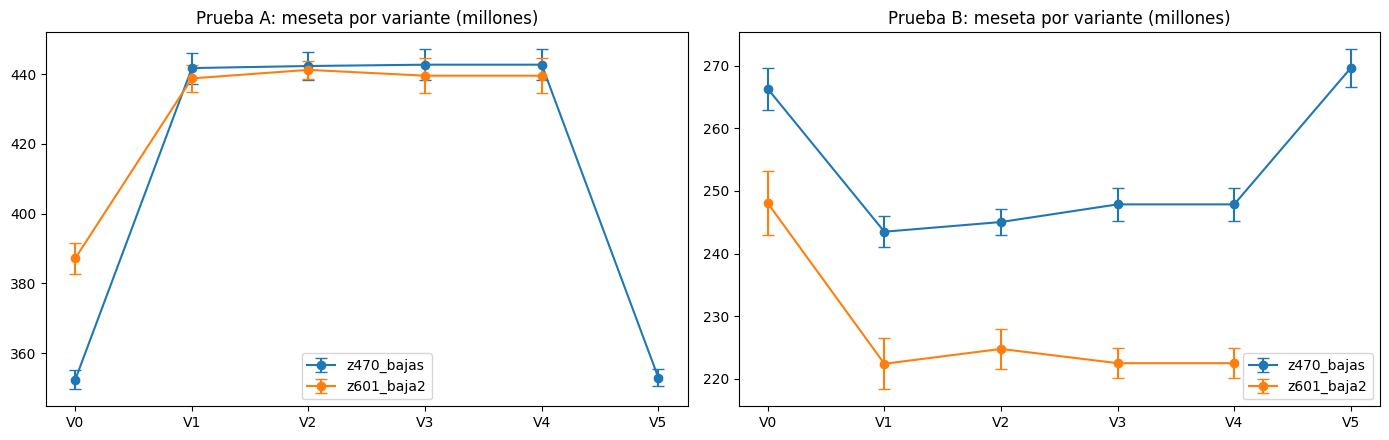

In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
for eje, prueba in zip(ejes, PRUEBAS):
    for config in CONFIGS:
        vs = [v for v in VARIANTES if corre(config, v)]
        medias = [por_semilla[(config, v, prueba)].mean() / 1e6 for v in vs]
        desvios = [por_semilla[(config, v, prueba)].std(ddof=1) / 1e6 if len(SEMILLAS_A_USAR) > 1 else 0 for v in vs]
        eje.errorbar(vs, medias, yerr=desvios, marker='o', capsize=4, label=config)
    eje.set_title(f"Prueba {prueba}: meseta por variante (millones)")
    eje.legend()
plt.tight_layout()
plt.show()

## 8. Elección (la decide el usuario)

- **Suma de A + B** en el N sugerido de cada variante (promedio de los N de A y B, redondeado a 500, entre 8.000 y 15.000), y diferencia contra V0.
- **Para el submit** (decisión 3): solo si la mejora en A + B supera el desvío entre semillas.
- **En el `03`:** `CONFIG` y `VARIANTE` (por ejemplo `'V4'`). El `03` lee `variantes.json` y el `resumen.csv` de esta carpeta.

Con `MODO_RAPIDO = True` es una sola semilla: **no sirve para decidir.**

In [24]:
filas = []
for config, variante in product(CONFIGS, VARIANTES):
    if not corre(config, variante):
        continue
    r = resumen.query('config == @config and variante == @variante').set_index('prueba')
    n = int(np.clip(round((r.loc['A', 'N_meseta'] + r.loc['B', 'N_meseta']) / 2 / 500) * 500, 8_000, 15_000))
    gA, gB = promedios[(config, variante, 'A')][n - 1], promedios[(config, variante, 'B')][n - 1]
    filas.append({'config': config, 'variante': variante, 'N_sugerido': n,
                  'A_en_N': gA / 1e6, 'B_en_N': gB / 1e6, 'A+B_en_N': (gA + gB) / 1e6,
                  'desvio_A+B': np.sqrt(r['ganancia_desvio'].pow(2).sum()) / 1e6})
eleccion = pd.DataFrame(filas)
eleccion['vs_V0'] = eleccion['A+B_en_N'] - eleccion.groupby('config')['A+B_en_N'].transform('first')
eleccion.style.format({c: '{:,.1f}' for c in ['A_en_N', 'B_en_N', 'A+B_en_N', 'desvio_A+B', 'vs_V0']} | {'N_sugerido': '{:,}'})

,config,variante,N_sugerido,A_en_N,B_en_N,A+B_en_N,desvio_A+B,vs_V0
0,z470_bajas,V0,"10,500",345.8,257.8,603.7,4.3,0.0
1,z470_bajas,V1,"11,500",430.8,230.3,661.1,5.1,57.4
2,z470_bajas,V2,"12,000",434.3,228.6,662.9,4.6,59.2
3,z470_bajas,V3,"11,000",429.9,239.9,669.8,5.1,66.1
4,z470_bajas,V4,"11,000",429.9,239.9,669.8,5.1,66.1
5,z470_bajas,V5,"10,500",347.3,261.4,608.6,3.9,5.0
6,z601_baja2,V0,"11,500",353.0,234.7,587.7,6.8,0.0
7,z601_baja2,V1,"10,000",433.9,215.4,649.3,5.6,61.6
8,z601_baja2,V2,"9,500",432.7,217.4,650.1,4.1,62.4
9,z601_baja2,V3,"9,500",430.4,218.3,648.8,5.5,61.0


## 9. Cierre

- **Registro:** anotar en `decisiones.md` el experimento #2 (resumen y comparación pareada) y qué variante se adopta para cada configuración.
- **Si hay submit:** en el `03`, fijar `CONFIG`, `VARIANTE` y un `NOMBRE_SUBMIT` nuevo.
- **Lo que sigue:** las variables nuevas (`05`, ficha de la etapa 5) sobre V5 si le gana a V0 con la regla de la ficha, o sobre la línea base si no. Después, el ensamble.